# 🔮 FORECAST H+1 (v2 — hybrid GARCH)
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### 🎯 Tujuan
Menghasilkan **prediksi volatilitas H+1** (satu hari bursa ke depan dari data historis terakhir) untuk enam/tujuh emiten sektor energi LQ45, menggunakan model XGBoost dan LSTM yang telah dilatih, lengkap dengan **klasifikasi risiko** (Low/Medium/High) per emiten.

### 🗂️ Susunan
- **CELL 1** — Import, konfigurasi path, definisi fitur X1/X2/Y, lookback per-emiten
- **CELL 2** — Fungsi bantu: forward/inverse transform, klasifikasi risiko kuantil
- **CELL 3** — Muat data terbaru per emiten
- **CELL 4** — Prediksi H+1 dengan XGBoost (ingat: model dilatih pada y×100 → dibagi 100)
- **CELL 5** — Prediksi H+1 dengan LSTM (keluaran = log-volatilitas → exp())
- **CELL 6** — Tabel ringkasan Forecast H+1 + klasifikasi risiko (→ Tabel jurnal/tesis)
- **CELL 7** — Grafik batang Forecast H+1: XGBoost vs LSTM (dari hasil CELL 6)
- **CELL 8 (OPSIONAL)** — Forecast rekursif H+1..H+N (ILUSTRATIF, bukan hasil utama)
- **CELL 9** — Visualisasi historis + titik prediksi H+1 per emiten

> ⚠️ **Catatan validitas:** prediksi H+1 valid penuh karena dihitung dari fitur riil hingga hari terakhir data. Forecast rekursif (CELL 8) hanya **ilustratif** — membekukan fitur non-volatilitas — sehingga TIDAK dijadikan temuan utama.

### 🔧 [v2] Revisi — konsisten dengan XGBoost v4 & LSTM v5
- 19 fitur (dibaca dari metadata PREP_01 v4) + `TARGET_MODE='ratio'`: prediksi = `GARCH_Forecast` × exp(koreksi model).
- Fitur **tidak di-clip** ke [0,1] (sama dengan PREP_03 v3).
- Pembanding H+1: **GARCH(1,1)** dan **Naive** (σ_t).
- Volatilitas aktual 1 Juli 2026 diambil dari `Volatilitas_Target` baris 30 Juni 2026 di `technical_features.csv` (harga Adj. Close yang sama dengan seluruh penelitian) — tidak lagi dari angka ketik manual.
- **Cek konsistensi:** prediksi H+1 = prediksi hari uji terakhir di `hasil_prediksi_xgboost.csv` / `hasil_prediksi_lstm.csv` (harus identik).
- Forecast rekursif dinonaktifkan (tidak valid untuk model hybrid).

---
## ⚙️ CELL 1 — Import, Konfigurasi Path, Fitur X1/X2/Y

In [1]:
import os, datetime, json as _json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras

SEED = 42
np.random.seed(SEED)

# ── ROOT auto-detect (identik notebook lain) ──
ROOT = Path(os.getcwd())
for _ in range(6):
    if (ROOT / '03_dataset').exists(): break
    ROOT = ROOT.parent
if not (ROOT / '03_dataset').exists():
    ROOT = Path(r'e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL     = ROOT / '03_dataset' / 'final'
DIR_XGB       = ROOT / '04_model' / 'xgboost'
DIR_LSTM      = ROOT / '04_model' / 'lstm'
DIR_TABEL     = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR    = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR):
    d.mkdir(parents=True, exist_ok=True)

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
# FIX v3: lookback BERBEDA per emiten (hasil CELL 4B tuning MODEL_lstm_v4).
LOOKBACK_DEFAULT = 10
def _muat_lookback_map():
    p = ROOT / '06_dokumen_tesis' / 'tabel' / 'tabel_hyperparameter_lstm.csv'
    peta = {e: LOOKBACK_DEFAULT for e in URUTAN_EMITEN}
    if not p.exists():
        print(f'  ⚠️  {p.name} tidak ada -> lookback {LOOKBACK_DEFAULT} untuk semua.')
        return peta
    d = pd.read_csv(p)
    kol_e = next((c for c in d.columns if c.lower() in ('emiten','kode_emiten')), None)
    kol_l = next((c for c in d.columns if 'lookback' in c.lower()), None)
    if kol_e and kol_l:
        for _, r in d.iterrows():
            if r[kol_e] in peta: peta[r[kol_e]] = int(r[kol_l])
        print(f'  ℹ️  Lookback per emiten: {peta}')
    return peta
LOOKBACK_MAP = _muat_lookback_map()
LOOKBACK = max(LOOKBACK_MAP.values())   # ambil terpanjang utk menyiapkan histori
TARGET_MODE = 'ratio'   # HARUS sama dengan MODEL_xgboost v4 & MODEL_lstm v5
N_HARI_FORECAST = 5    # untuk mode rekursif H+1..H+N (opsional, CELL 7)

def muat_csv(path, **kw):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File TIDAK ADA: {path.resolve()}')
    df = pd.read_csv(path, **kw)
    print(f'LOAD  : {path.resolve()}  ({len(df):,} baris x {df.shape[1]} kolom)')
    return df

# ── FIX konsisten dgn seluruh pipeline v2: KOLOM_X1/KOLOM_Y dari metadata PREP_01 ──
PATH_META_X1 = DIR_PROCESSED / 'technical_features_meta.json'
if PATH_META_X1.exists():
    with open(PATH_META_X1, 'r', encoding='utf-8') as f:
        _meta = _json.load(f)
    KOLOM_X1 = _meta['kolom_x1']
    KOLOM_Y  = _meta['kolom_y']
else:
    KOLOM_X1 = ['Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
                'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14',
                'Stoch_K', 'Stoch_D', 'Volume_ZScore']
    KOLOM_Y = 'Volatilitas_Target'

KOLOM_X2 = ['Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']
KOLOM_X = KOLOM_X1 + KOLOM_X2

print('='*66)
print('  🔮 FORECAST OUT-OF-SAMPLE — KONFIGURASI SIAP')
print('='*66)
print(f'ROOT       : {ROOT}')
print(f'KOLOM_X1   : {KOLOM_X1}')
print(f'KOLOM_X2   : {KOLOM_X2}')
print(f'KOLOM_Y    : {KOLOM_Y}')
print(f'LOOKBACK   : {LOOKBACK}')
print('='*66)

  ℹ️  Lookback per emiten: {'ADRO': 15, 'ADMR': 15, 'ITMG': 15, 'PTBA': 10, 'MEDC': 15, 'AKRA': 15, 'PGAS': 15}
  🔮 FORECAST OUT-OF-SAMPLE — KONFIGURASI SIAP
ROOT       : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
KOLOM_X1   : ['Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5', 'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore', 'R_Exit', 'GARCH_Forecast']
KOLOM_X2   : ['Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']
KOLOM_Y    : Volatilitas_Target
LOOKBACK   : 15


---
## 🔧 CELL 2 — Fungsi Bantu: Forward/Inverse Transform, Kategori Risiko

In [2]:
def inverse_lstm(nilai_log):
    '''FIX v3 — KRITIS. MODEL_lstm_v4 dilatih pada LOG-TARGET: keluaran model
    adalah log(volatilitas). Pengembalian ke skala asli memakai exp(),
    BUKAN inverse MinMax. Salah transform di sini tidak memunculkan error,
    hanya angka prediksi yang keliru total.'''
    import numpy as _np
    return float(_np.exp(float(nilai_log)))

def forward_transform(nilai_asli, scaler_df, kolom):
    """Ubah nilai skala ASLI -> MinMax [0,1], pakai min/max HASIL TRAIN (PREP_03).
    Kebalikan dari inverse_transform. Dipakai untuk scale data TERBARU (belum
    pernah dilihat scaler) sebelum masuk model — TIDAK re-fit scaler (no leakage),
    murni transform pakai parameter yang sudah dikunci saat training."""
    if scaler_df is None or kolom not in scaler_df.index:
        return np.asarray(nilai_asli, dtype=float)
    cmin = float(scaler_df.loc[kolom, 'min']); cmax = float(scaler_df.loc[kolom, 'max'])
    rentang = (cmax - cmin) if (cmax - cmin) != 0 else 1.0
    hasil = (np.asarray(nilai_asli, dtype=float) - cmin) / rentang
    return hasil   # [v2] TANPA clip — konsisten dengan PREP_03 v3

def inverse_transform(nilai_scaled, scaler_df, kolom):
    """Kembalikan nilai ter-MinMax-scale ke skala asli. Identik seluruh notebook lain."""
    if scaler_df is None or kolom not in scaler_df.index:
        return np.asarray(nilai_scaled, dtype=float)
    cmin = float(scaler_df.loc[kolom, 'min']); cmax = float(scaler_df.loc[kolom, 'max'])
    return np.asarray(nilai_scaled, dtype=float) * (cmax - cmin) + cmin

def hitung_threshold_risiko(vol_historis_series, q_low=0.33, q_high=0.66):
    """Hitung threshold kuantil 33%/66% dari distribusi HISTORIS Volatilitas_Target
    untuk SATU emiten (per-emiten, bukan global) — skala volatilitas beda jauh
    antar emiten (mis. PGAS historis lebih stabil dari MEDC), threshold global
    akan bias ke emiten yang secara natural lebih/kurang volatil."""
    data = vol_historis_series.dropna()
    if data.empty:
        raise ValueError("Data historis volatilitas kosong — cek filter emiten.")
    q33 = data.quantile(q_low)
    q66 = data.quantile(q_high)
    return q33, q66


def kategori_risiko(vol, vol_historis_series):
    """Klasifikasi RULE-BASED (bukan model ML) — threshold kuantil 33%/66%
    dari distribusi historis Volatilitas_Target emiten yang sama. Label
    Inggris (Low/Medium/High Risk) untuk konsisten dengan istilah baku
    manajemen risiko keuangan di Bab 4/5 tesis."""
    q33, q66 = hitung_threshold_risiko(vol_historis_series)
    if vol < q33:
        return 'Low Risk'
    elif vol < q66:
        return 'Medium Risk'
    else:
        return 'High Risk'

print('✅ Fungsi bantu siap (forward/inverse transform, klasifikasi risiko kuantil per-emiten).')

# ── [v2] Inversi prediksi model hybrid ──
def xgb_ke_vol(pred, g_asli, y_scaler=None):
    """XGBoost v4: ratio -> GARCH x exp(pred/100); level -> pred/100 lalu inverse MinMax."""
    if TARGET_MODE == 'ratio':
        return float(max(g_asli, 1e-8) * np.exp(pred / 100))
    return float(max(inverse_transform(pred / 100, y_scaler, KOLOM_Y), 0))

def lstm_ke_vol(z, g_asli):
    """LSTM v5: ratio -> GARCH x exp(z); log -> exp(z)."""
    return float(max(g_asli, 1e-8) * np.exp(z)) if TARGET_MODE == 'ratio' else float(np.exp(z))

✅ Fungsi bantu siap (forward/inverse transform, klasifikasi risiko kuantil per-emiten).


---
## 📂 CELL 3 — Muat Data Terbaru per Emiten (untuk Forecast H+1)

In [3]:
print('='*70)
print('  📂 CELL 3 — MUAT DATA TERBARU PER EMITEN')
print('='*70)

df_tek = muat_csv(DIR_PROCESSED / 'technical_features.csv')
df_tek['Date'] = pd.to_datetime(df_tek['Date'])

df_sen = muat_csv(DIR_PROCESSED / 'skor_sentimen_harian.csv')
df_sen['Date'] = pd.to_datetime(df_sen['Date'])

dict_terbaru = {}   # {emiten: DataFrame LOOKBACK baris terakhir, fitur lengkap}
dict_scaler  = {}

for emiten in URUTAN_EMITEN:
    d_tek = df_tek[df_tek['Emiten'] == emiten].sort_values('Date')
    d_sen = df_sen[df_sen['Emiten'] == emiten].sort_values('Date')

    d = pd.merge(d_tek, d_sen[['Date'] + KOLOM_X2], on='Date', how='left')
    for c in KOLOM_X2:
        d[c] = d[c].fillna(0.0 if c != 'Ada_Berita' else 0)

    kolom_hilang = [c for c in KOLOM_X1 + KOLOM_X2 if c not in d.columns]
    if kolom_hilang:
        print(f'  ⚠️  {emiten}: kolom hilang {kolom_hilang}, skip')
        continue

    d = d.dropna(subset=KOLOM_X1).reset_index(drop=True)
    if len(d) < LOOKBACK:
        print(f'  ⚠️  {emiten}: hanya {len(d)} baris valid (< LOOKBACK={LOOKBACK}), skip')
        continue

    p_sc = DIR_FINAL / f'scaler_params_{emiten}.csv'
    scaler = pd.read_csv(p_sc, index_col=0, encoding='utf-8-sig') if p_sc.exists() else None
    if scaler is None:
        print(f'  ⚠️  {emiten}: scaler_params tidak ditemukan, skip')
        continue

    dict_terbaru[emiten] = d.tail(LOOKBACK).reset_index(drop=True)
    dict_scaler[emiten]  = scaler

    tgl_terakhir = d['Date'].iloc[-1].date()
    print(f'  ✅ {emiten}: data s/d {tgl_terakhir} siap untuk forecast H+1 '
          f'({tgl_terakhir + pd.Timedelta(days=1)} kalender, sesuaikan hari bursa)')

print(f'\nTotal emiten siap: {len(dict_terbaru)}/{len(URUTAN_EMITEN)}')

  📂 CELL 3 — MUAT DATA TERBARU PER EMITEN
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features.csv  (7,494 baris x 27 kolom)
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\skor_sentimen_harian.csv  (7,518 baris x 6 kolom)
  ✅ ADRO: data s/d 2026-06-30 siap untuk forecast H+1 (2026-07-01 kalender, sesuaikan hari bursa)
  ✅ ADMR: data s/d 2026-06-30 siap untuk forecast H+1 (2026-07-01 kalender, sesuaikan hari bursa)
  ✅ ITMG: data s/d 2026-06-30 siap untuk forecast H+1 (2026-07-01 kalender, sesuaikan hari bursa)
  ✅ PTBA: data s/d 2026-06-30 siap untuk forecast H+1 (2026-07-01 kalender, sesuaikan hari bursa)
  ✅ MEDC: data s/d 2026-06-30 siap untuk forecast H+1 (2026-07-01 kalender, sesuaikan hari bursa)
  ✅ AKRA: data s/d 2026-06-30 siap untuk forecast H+1 (2026-07-

---
## 🌳 CELL 4 — Prediksi H+1 dengan XGBoost

Memakai **1 baris fitur terakhir** (hari bursa paling akhir) → model XGBoost (tabular, tidak butuh sequence). **Penting:** model XGBoost dilatih pada target `y×100`, sehingga prediksi mentah **dibagi 100** sebelum *inverse-transform* ke skala volatilitas asli.

In [4]:
print('='*70)
print('  🌳 CELL 4 — PREDIKSI H+1 — XGBOOST')
print('='*70)

hasil_xgb_h1 = {}

for emiten in dict_terbaru:
    path_mdl = DIR_XGB / f'xgboost_{emiten}.pkl'
    if not path_mdl.exists():
        print(f'  ⚠️  {emiten}: model XGBoost tidak ditemukan, skip'); continue

    model  = joblib.load(path_mdl)
    scaler = dict_scaler[emiten]
    baris_terakhir = dict_terbaru[emiten].iloc[[-1]]   # 1 baris terakhir (DataFrame, bukan Series)

    kolom_x = list(model.feature_names_in_) if hasattr(model, 'feature_names_in_') else KOLOM_X
    kolom_x_hilang = [c for c in kolom_x if c not in baris_terakhir.columns]
    if kolom_x_hilang:
        print(f'  ❌ {emiten}: fitur hilang {kolom_x_hilang}, skip'); continue

    # Scale fitur (forward transform, pakai scaler HASIL TRAIN — tidak re-fit)
    X_scaled = np.array([[forward_transform(baris_terakhir[c].values[0], scaler, c)
                           for c in kolom_x]])

    # [v2] model hybrid: prediksi = GARCH_Forecast_t x exp(koreksi/100)
    g_asli = float(baris_terakhir['GARCH_Forecast'].values[0])     # skala asli (technical_features)
    y_pred = xgb_ke_vol(float(model.predict(X_scaled)[0]), g_asli, scaler)

    tgl_basis = baris_terakhir['Date'].values[0]
    hasil_xgb_h1[emiten] = {'Tanggal_Basis': pd.Timestamp(tgl_basis), 'Vol_Prediksi_H1': y_pred}
    print(f'  ✅ {emiten:<5}: basis={pd.Timestamp(tgl_basis).date()} → Vol_H+1 = {y_pred:.6f}')

print(f'\nTotal diprediksi: {len(hasil_xgb_h1)} emiten')

  🌳 CELL 4 — PREDIKSI H+1 — XGBOOST
  ✅ ADRO : basis=2026-06-30 → Vol_H+1 = 0.024293
  ✅ ADMR : basis=2026-06-30 → Vol_H+1 = 0.048689
  ✅ ITMG : basis=2026-06-30 → Vol_H+1 = 0.016504
  ✅ PTBA : basis=2026-06-30 → Vol_H+1 = 0.025863
  ✅ MEDC : basis=2026-06-30 → Vol_H+1 = 0.022835
  ✅ AKRA : basis=2026-06-30 → Vol_H+1 = 0.026997
  ✅ PGAS : basis=2026-06-30 → Vol_H+1 = 0.037001

Total diprediksi: 7 emiten


---
## 🧠 CELL 5 — Prediksi H+1 dengan LSTM

Memakai **sequence lookback hari terakhir** (per-emiten dari tabel hyperparameter) → model LSTM. **Penting:** keluaran LSTM adalah **log-volatilitas**, sehingga dikembalikan ke skala asli dengan `exp()`, BUKAN inverse MinMax.

In [5]:
print('='*70)
print('  🧠 CELL 5 — PREDIKSI H+1 — LSTM')
print('='*70)

hasil_lstm_h1 = {}

for emiten in dict_terbaru:
    path_mdl = DIR_LSTM / f'lstm_best_{emiten}.keras'
    if not path_mdl.exists():
        print(f'  ⚠️  {emiten}: model LSTM tidak ditemukan, skip'); continue

    model  = keras.models.load_model(path_mdl, compile=False)
    scaler = dict_scaler[emiten]
    _lb    = LOOKBACK_MAP.get(emiten, LOOKBACK_DEFAULT)   # FIX v3: per emiten
    seq_df = dict_terbaru[emiten].iloc[-_lb:]   # _lb baris terakhir, kronologis

    n_exp = model.input_shape[-1]
    if n_exp != len(KOLOM_X):
        print(f'  ❌ {emiten}: fitur LSTM ({len(KOLOM_X)}) != input model ({n_exp}), skip'); continue

    X_scaled = np.array([[forward_transform(seq_df[c].values[i], scaler, c)
                           for c in KOLOM_X]
                          for i in range(len(seq_df))])
    X_scaled = X_scaled[np.newaxis, :, :]   # shape (1, LOOKBACK, n_fitur)

    z_pred = float(model.predict(X_scaled, verbose=0).flatten()[0])
    g_asli = float(seq_df['GARCH_Forecast'].values[-1])            # GARCH_Forecast hari t (skala asli)
    y_pred = lstm_ke_vol(z_pred, g_asli)                            # [v2] hybrid

    tgl_basis = seq_df['Date'].iloc[-1]
    hasil_lstm_h1[emiten] = {'Tanggal_Basis': pd.Timestamp(tgl_basis), 'Vol_Prediksi_H1': y_pred}
    print(f'  ✅ {emiten:<5}: basis={pd.Timestamp(tgl_basis).date()} → Vol_H+1 = {y_pred:.6f}')

print(f'\nTotal diprediksi: {len(hasil_lstm_h1)} emiten')

  🧠 CELL 5 — PREDIKSI H+1 — LSTM
  ✅ ADRO : basis=2026-06-30 → Vol_H+1 = 0.024775
  ✅ ADMR : basis=2026-06-30 → Vol_H+1 = 0.048364
  ✅ ITMG : basis=2026-06-30 → Vol_H+1 = 0.016438
  ✅ PTBA : basis=2026-06-30 → Vol_H+1 = 0.025435
  ✅ MEDC : basis=2026-06-30 → Vol_H+1 = 0.022950
  ✅ AKRA : basis=2026-06-30 → Vol_H+1 = 0.026916
  ✅ PGAS : basis=2026-06-30 → Vol_H+1 = 0.036786

Total diprediksi: 7 emiten


---
## 📋 CELL 6 — Tabel Ringkasan Forecast H+1 + Klasifikasi Risiko

In [6]:
print('='*70)
print('  FORECAST H+1 — XGBoost vs LSTM + KLASIFIKASI RISIKO')
print('='*70)

baris = []
for emiten in URUTAN_EMITEN:
    if emiten not in hasil_xgb_h1 or emiten not in hasil_lstm_h1:
        continue
    d_hist = df_tek[df_tek['Emiten'] == emiten][KOLOM_Y].dropna()  # basis kuantil: Volatilitas_Target historis

    v_xgb  = hasil_xgb_h1[emiten]['Vol_Prediksi_H1']
    v_lstm = hasil_lstm_h1[emiten]['Vol_Prediksi_H1']
    tgl    = hasil_xgb_h1[emiten]['Tanggal_Basis']
    v_garch = float(dict_terbaru[emiten]['GARCH_Forecast'].values[-1])   # [v2] pembanding
    v_naive = float(dict_terbaru[emiten]['Volatilitas'].values[-1])

    q33, q66 = hitung_threshold_risiko(d_hist)
    risiko_xgb  = kategori_risiko(v_xgb, d_hist)
    risiko_lstm = kategori_risiko(v_lstm, d_hist)

    # ── Format output ringkas per emiten (sesuai spesifikasi) ──
    print(f"Emiten               : {emiten}")
    print(f"Prediksi Volatilitas : XGBoost={v_xgb:.4f}  |  LSTM={v_lstm:.4f}")
    print(f"Kategori Risiko      : XGBoost={risiko_xgb}  |  LSTM={risiko_lstm}")
    print(f"  (threshold {emiten}: Q33={q33:.4f}, Q66={q66:.4f})")
    print('-' * 70)

    baris.append({
        'Emiten': emiten,
        'Basis (hari terakhir data)': tgl.date(),
        'Vol_Prediksi_XGBoost': round(v_xgb, 6),
        'Vol_Prediksi_LSTM': round(v_lstm, 6),
        'Vol_Prediksi_GARCH': round(v_garch, 6),
        'Vol_Prediksi_Naive': round(v_naive, 6),
        'Selisih_Absolut': round(abs(v_xgb - v_lstm), 6),
        'Threshold_Q33': round(q33, 6),
        'Threshold_Q66': round(q66, 6),
        'Kategori_Risiko_XGB': risiko_xgb,
        'Kategori_Risiko_LSTM': risiko_lstm,
    })

df_forecast_h1 = pd.DataFrame(baris)
pd.set_option('display.width', 220, 'display.max_columns', None)
print()
print(df_forecast_h1.to_string(index=False))

path_out = DIR_TABEL / 'tabel_forecast_h1.csv'
df_forecast_h1.to_csv(path_out, index=False, encoding='utf-8-sig')
print(f'\n💾 Tabel disimpan: {path_out}')
print('\n⚠️  Ini prediksi H+1 (1 hari bursa ke depan dari data terakhir) — VALID PENUH,')
print('   dihitung dari fitur riil sampai hari terakhir data historis.')
print('ℹ️  Kategori risiko: rule-based (bukan model ML), threshold kuantil')
print('   33%/66% dari distribusi historis Volatilitas_Target PER EMITEN.')

  FORECAST H+1 — XGBoost vs LSTM + KLASIFIKASI RISIKO
Emiten               : ADRO
Prediksi Volatilitas : XGBoost=0.0243  |  LSTM=0.0248
Kategori Risiko      : XGBoost=Medium Risk  |  LSTM=Medium Risk
  (threshold ADRO: Q33=0.0202, Q66=0.0261)
----------------------------------------------------------------------
Emiten               : ADMR
Prediksi Volatilitas : XGBoost=0.0487  |  LSTM=0.0484
Kategori Risiko      : XGBoost=High Risk  |  LSTM=High Risk
  (threshold ADMR: Q33=0.0278, Q66=0.0372)
----------------------------------------------------------------------
Emiten               : ITMG
Prediksi Volatilitas : XGBoost=0.0165  |  LSTM=0.0164
Kategori Risiko      : XGBoost=Medium Risk  |  LSTM=Medium Risk
  (threshold ITMG: Q33=0.0131, Q66=0.0213)
----------------------------------------------------------------------
Emiten               : PTBA
Prediksi Volatilitas : XGBoost=0.0259  |  LSTM=0.0254
Kategori Risiko      : XGBoost=High Risk  |  LSTM=High Risk
  (threshold PTBA: Q33=0.015

---
## ✅ CELL 10 — Verifikasi H+1 terhadap Volatilitas Aktual

Membandingkan prediksi H+1 dengan **volatilitas aktual 1 Juli 2026** (std dev log return 20 hari dari harga riil). Menghitung MAPE per emiten dan rata-rata — bukti keberhasilan model secara *out-of-sample*.

In [7]:
print('='*70)
print('  ✅ CELL 10 — VERIFIKASI PREDIKSI H+1 vs VOLATILITAS AKTUAL (1 Juli 2026)')
print('='*70)
# [v2] Aktual = Volatilitas_Target baris basis (30 Juni 2026) = sigma 20 hari pada 1 Juli 2026,
# dihitung dari Adj. Close yang SAMA dengan seluruh penelitian (PREP_01 v4, buffer Juli 2026).
baris = []
for em in URUTAN_EMITEN:
    if em not in hasil_xgb_h1 or em not in hasil_lstm_h1:
        continue
    d_last = dict_terbaru[em].iloc[-1]
    v_akt  = float(d_last[KOLOM_Y])
    v_xgb, v_lstm = hasil_xgb_h1[em]['Vol_Prediksi_H1'], hasil_lstm_h1[em]['Vol_Prediksi_H1']
    v_garch, v_naive = float(d_last['GARCH_Forecast']), float(d_last['Volatilitas'])
    err = lambda v: abs(v - v_akt) / v_akt * 100
    baris.append({'Emiten': em, 'Aktual': v_akt, 'XGBoost': v_xgb, 'LSTM': v_lstm,
                  'GARCH(1,1)': v_garch, 'Naive': v_naive,
                  'Err_XGB_%': err(v_xgb), 'Err_LSTM_%': err(v_lstm),
                  'Err_GARCH_%': err(v_garch), 'Err_Naive_%': err(v_naive)})
df_verifikasi = pd.DataFrame(baris)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
print(df_verifikasi.to_string(index=False))
print('\n  Rata-rata absolute percentage error H+1:')
for k in ['XGB', 'LSTM', 'GARCH', 'Naive']:
    print(f'    {k:6}: {df_verifikasi[f"Err_{k}_%"].mean():.2f}%')
df_verifikasi.to_csv(DIR_TABEL / 'verifikasi_H1_vs_aktual.csv', index=False, encoding='utf-8-sig')
print(f"\n💾 Tersimpan: {DIR_TABEL / 'verifikasi_H1_vs_aktual.csv'}")

# ── Cek konsistensi dengan hari uji terakhir di notebook model ──
print('\n  Cek konsistensi vs hasil_prediksi_*.csv (hari uji terakhir = basis 30/06/2026):')
for nama, f, kol in [('XGBoost', 'hasil_prediksi_xgboost.csv', 'XGBoost'), ('LSTM', 'hasil_prediksi_lstm.csv', 'LSTM')]:
    p = DIR_TABEL / f
    if not p.exists():
        print(f'    {nama}: {f} tidak ada, dilewati'); continue
    hp = pd.read_csv(p); hp['Date'] = pd.to_datetime(hp['Date'])
    for em in df_verifikasi['Emiten']:
        last = hp[hp['Emiten'] == em].sort_values('Date').iloc[-1]
        v_nb = float(df_verifikasi.loc[df_verifikasi.Emiten == em, kol].iloc[0])
        ok = abs(last['Y_Prediksi'] - v_nb) / max(abs(v_nb), 1e-9) < 1e-3 and abs(last['Y_Aktual'] - float(df_verifikasi.loc[df_verifikasi.Emiten == em, 'Aktual'].iloc[0])) < 1e-6
        print(f"    {nama:7} {em}: notebook model={last['Y_Prediksi']:.6f} | forecast={v_nb:.6f} -> {'OK' if ok else 'BERBEDA (cek model tersimpan/urutan fitur)'}")

  ✅ CELL 10 — VERIFIKASI PREDIKSI H+1 vs VOLATILITAS AKTUAL (1 Juli 2026)
Emiten  Aktual  XGBoost   LSTM  GARCH(1,1)  Naive  Err_XGB_%  Err_LSTM_%  Err_GARCH_%  Err_Naive_%
  ADRO  0.0241   0.0243 0.0248      0.0246 0.0241     0.9631      2.9665       2.4080       0.2940
  ADMR  0.0486   0.0487 0.0484      0.0487 0.0494     0.1785      0.4906       0.3030       1.6751
  ITMG  0.0165   0.0165 0.0164      0.0168 0.0162     0.0064      0.4027       1.8125       1.7751
  PTBA  0.0255   0.0259 0.0254      0.0259 0.0254     1.4809      0.1998       1.6502       0.2123
  MEDC  0.0240   0.0228 0.0229      0.0227 0.0298     4.7559      4.2749       5.1165      24.3218
  AKRA  0.0266   0.0270 0.0269      0.0270 0.0278     1.3993      1.0945       1.5907       4.3763
  PGAS  0.0364   0.0370 0.0368      0.0371 0.0364     1.5147      0.9255       1.8463       0.0000

  Rata-rata absolute percentage error H+1:
    XGB   : 1.47%
    LSTM  : 1.48%
    GARCH : 2.10%
    Naive : 4.66%

💾 Tersimpan: e:\D

---
## 📊 CELL 11 — Grafik 3-Batang: Prediksi vs Aktual

Menampilkan prediksi XGBoost, LSTM, dan nilai aktual berdampingan per emiten, sehingga kedekatan prediksi terhadap kenyataan terlihat langsung.

  📊 CELL 11 — GRAFIK 3-BATANG: PREDIKSI H+1 vs AKTUAL


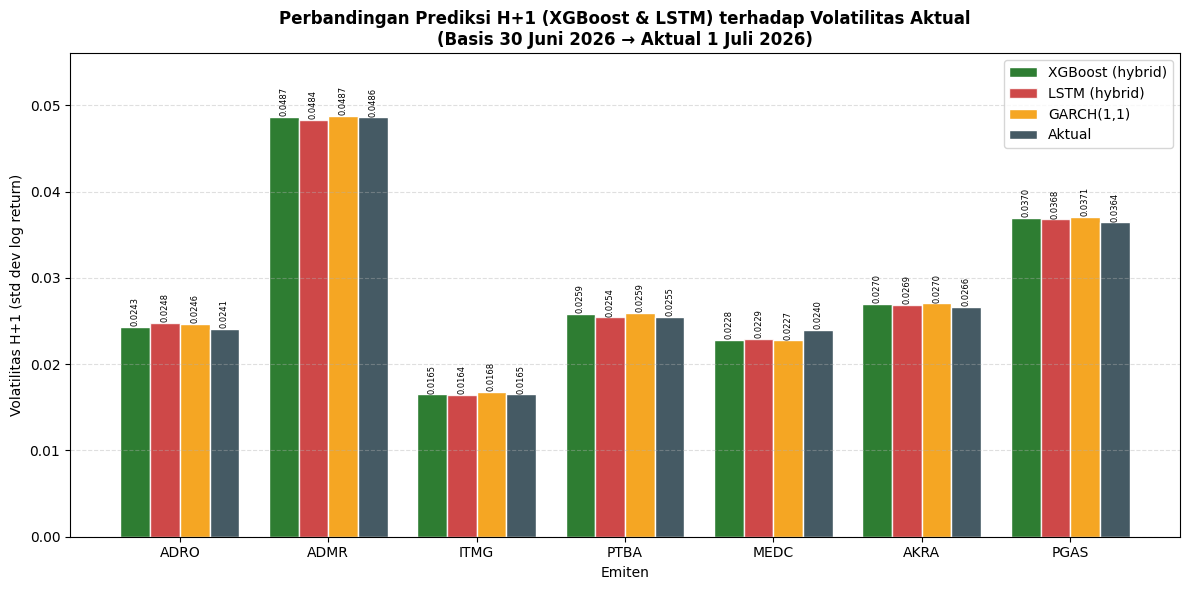

💾 Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\forecast_h1_vs_aktual.png


In [8]:
print('='*70)
print('  📊 CELL 11 — GRAFIK 3-BATANG: PREDIKSI H+1 vs AKTUAL')
print('='*70)

emiten = df_verifikasi['Emiten'].tolist()
xgb    = df_verifikasi['XGBoost'].tolist()
lstm   = df_verifikasi['LSTM'].tolist()
garch  = df_verifikasi['GARCH(1,1)'].tolist()
aktual = df_verifikasi['Aktual'].tolist()

x = np.arange(len(emiten)); w = 0.2
fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x - 1.5*w, xgb,    w, label='XGBoost (hybrid)', color='#2E7D32', edgecolor='white')
b2 = ax.bar(x - 0.5*w, lstm,   w, label='LSTM (hybrid)',    color='#C62828', edgecolor='white', alpha=.85)
b4 = ax.bar(x + 0.5*w, garch,  w, label='GARCH(1,1)',       color='#F5A623', edgecolor='white')
b3 = ax.bar(x + 1.5*w, aktual, w, label='Aktual',           color='#455A64', edgecolor='white')

ax.set_ylabel('Volatilitas H+1 (std dev log return)')
ax.set_xlabel('Emiten')
ax.set_title('Perbandingan Prediksi H+1 (XGBoost & LSTM) terhadap Volatilitas Aktual\n'
             '(Basis 30 Juni 2026 \u2192 Aktual 1 Juli 2026)', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(emiten)
ax.legend(); ax.grid(axis='y', linestyle='--', alpha=0.4)

for bars in (b1, b2, b4, b3):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.4f}', xy=(bar.get_x()+bar.get_width()/2, h),
                    xytext=(0,2), textcoords='offset points', ha='center', fontsize=6, rotation=90)

ax.set_ylim(0, max(max(xgb), max(lstm), max(garch), max(aktual)) * 1.15)
plt.tight_layout()
path_fig = DIR_GAMBAR / 'forecast_h1_vs_aktual.png'
plt.savefig(path_fig, dpi=300, bbox_inches='tight')
plt.show()
print(f'💾 Gambar disimpan: {path_fig}')

---
## 📊 CELL 7 — Grafik Batang Forecast H+1 (XGBoost vs LSTM)

Grafik ini mengambil angka **langsung dari `df_forecast_h1`** (hasil CELL 6), sehingga selalu konsisten dengan tabel — tidak ada angka yang ditulis manual.

  📊 CELL 7 — GRAFIK BATANG FORECAST H+1: XGBoost vs LSTM


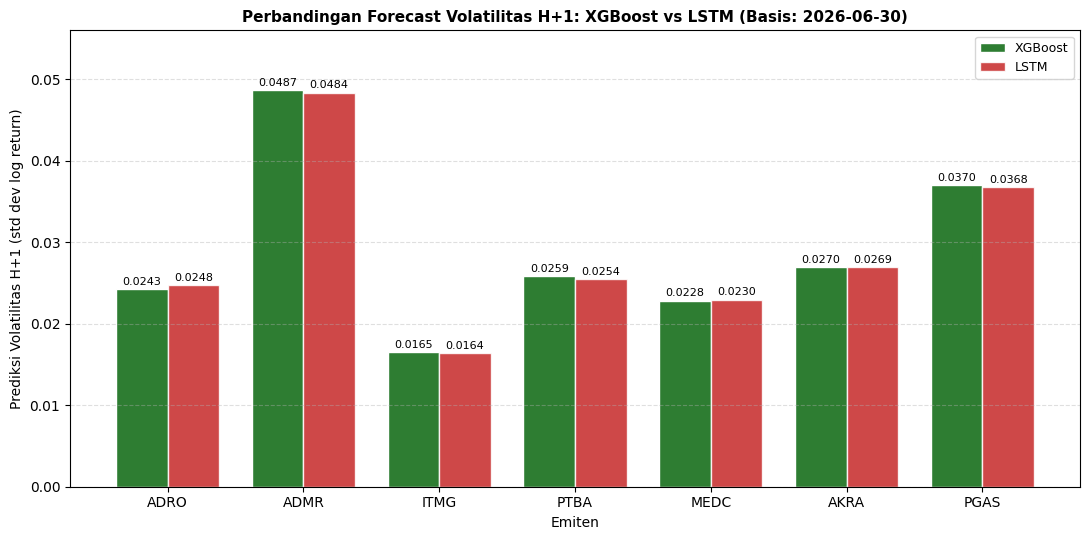

💾 Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\forecast_h1_xgboost_vs_lstm.png


In [9]:
print('='*70)
print('  📊 CELL 7 — GRAFIK BATANG FORECAST H+1: XGBoost vs LSTM')
print('='*70)

# Ambil angka LANGSUNG dari hasil CELL 6 (df_forecast_h1) — tidak hardcode,
# sehingga grafik selalu sinkron dengan tabel.
emiten_plot = df_forecast_h1['Emiten'].tolist()
xgb  = df_forecast_h1['Vol_Prediksi_XGBoost'].tolist()
lstm = df_forecast_h1['Vol_Prediksi_LSTM'].tolist()

x = np.arange(len(emiten_plot)); w = 0.38
fig, ax = plt.subplots(figsize=(11, 5.5))
b1 = ax.bar(x - w/2, xgb,  w, label='XGBoost', color='#2E7D32', edgecolor='white')
b2 = ax.bar(x + w/2, lstm, w, label='LSTM',    color='#C62828', edgecolor='white', alpha=.85)

# Basis tanggal (ambil dari kolom tabel bila ada)
tgl_basis = ''
if 'Basis (hari terakhir data)' in df_forecast_h1.columns and len(df_forecast_h1):
    tgl_basis = f" (Basis: {df_forecast_h1['Basis (hari terakhir data)'].iloc[0]})"

ax.set_ylabel('Prediksi Volatilitas H+1 (std dev log return)', fontsize=10)
ax.set_xlabel('Emiten', fontsize=10)
ax.set_title(f'Perbandingan Forecast Volatilitas H+1: XGBoost vs LSTM{tgl_basis}',
             fontsize=11, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(emiten_plot)
ax.legend(fontsize=9); ax.grid(axis='y', linestyle='--', alpha=0.4)

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.4f}', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', fontsize=8)

ax.set_ylim(0, max(max(xgb), max(lstm)) * 1.15)
plt.tight_layout()
path_fig = DIR_GAMBAR / 'forecast_h1_xgboost_vs_lstm.png'
plt.savefig(path_fig, dpi=300, bbox_inches='tight')
plt.show()
print(f'💾 Gambar disimpan: {path_fig}')

---
## ⚠️ CELL 8 — Forecast Rekursif (DINONAKTIFKAN di v2)
Tidak valid untuk model hybrid: rekursi memerlukan GARCH, R_Exit, dan fitur lain hari berikutnya yang belum diketahui. Hanya H+1 yang dilaporkan.

In [10]:
JALANKAN_MODE_REKURSIF = False
hasil_rekursif = {}
print('Mode rekursif dinonaktifkan (v2) — hanya H+1 yang valid.')

Mode rekursif dinonaktifkan (v2) — hanya H+1 yang valid.


---
## 📈 CELL 9 — Visualisasi: Historis + Titik Forecast H+1 per Emiten

Menampilkan 40 hari historis + titik prediksi H+1 (XGBoost & LSTM), dengan pita zona risiko (Low/Medium/High) sebagai konteks visual.

  📊 VISUALISASI FORECAST PER EMITEN (VERSI DIPERBARUI)


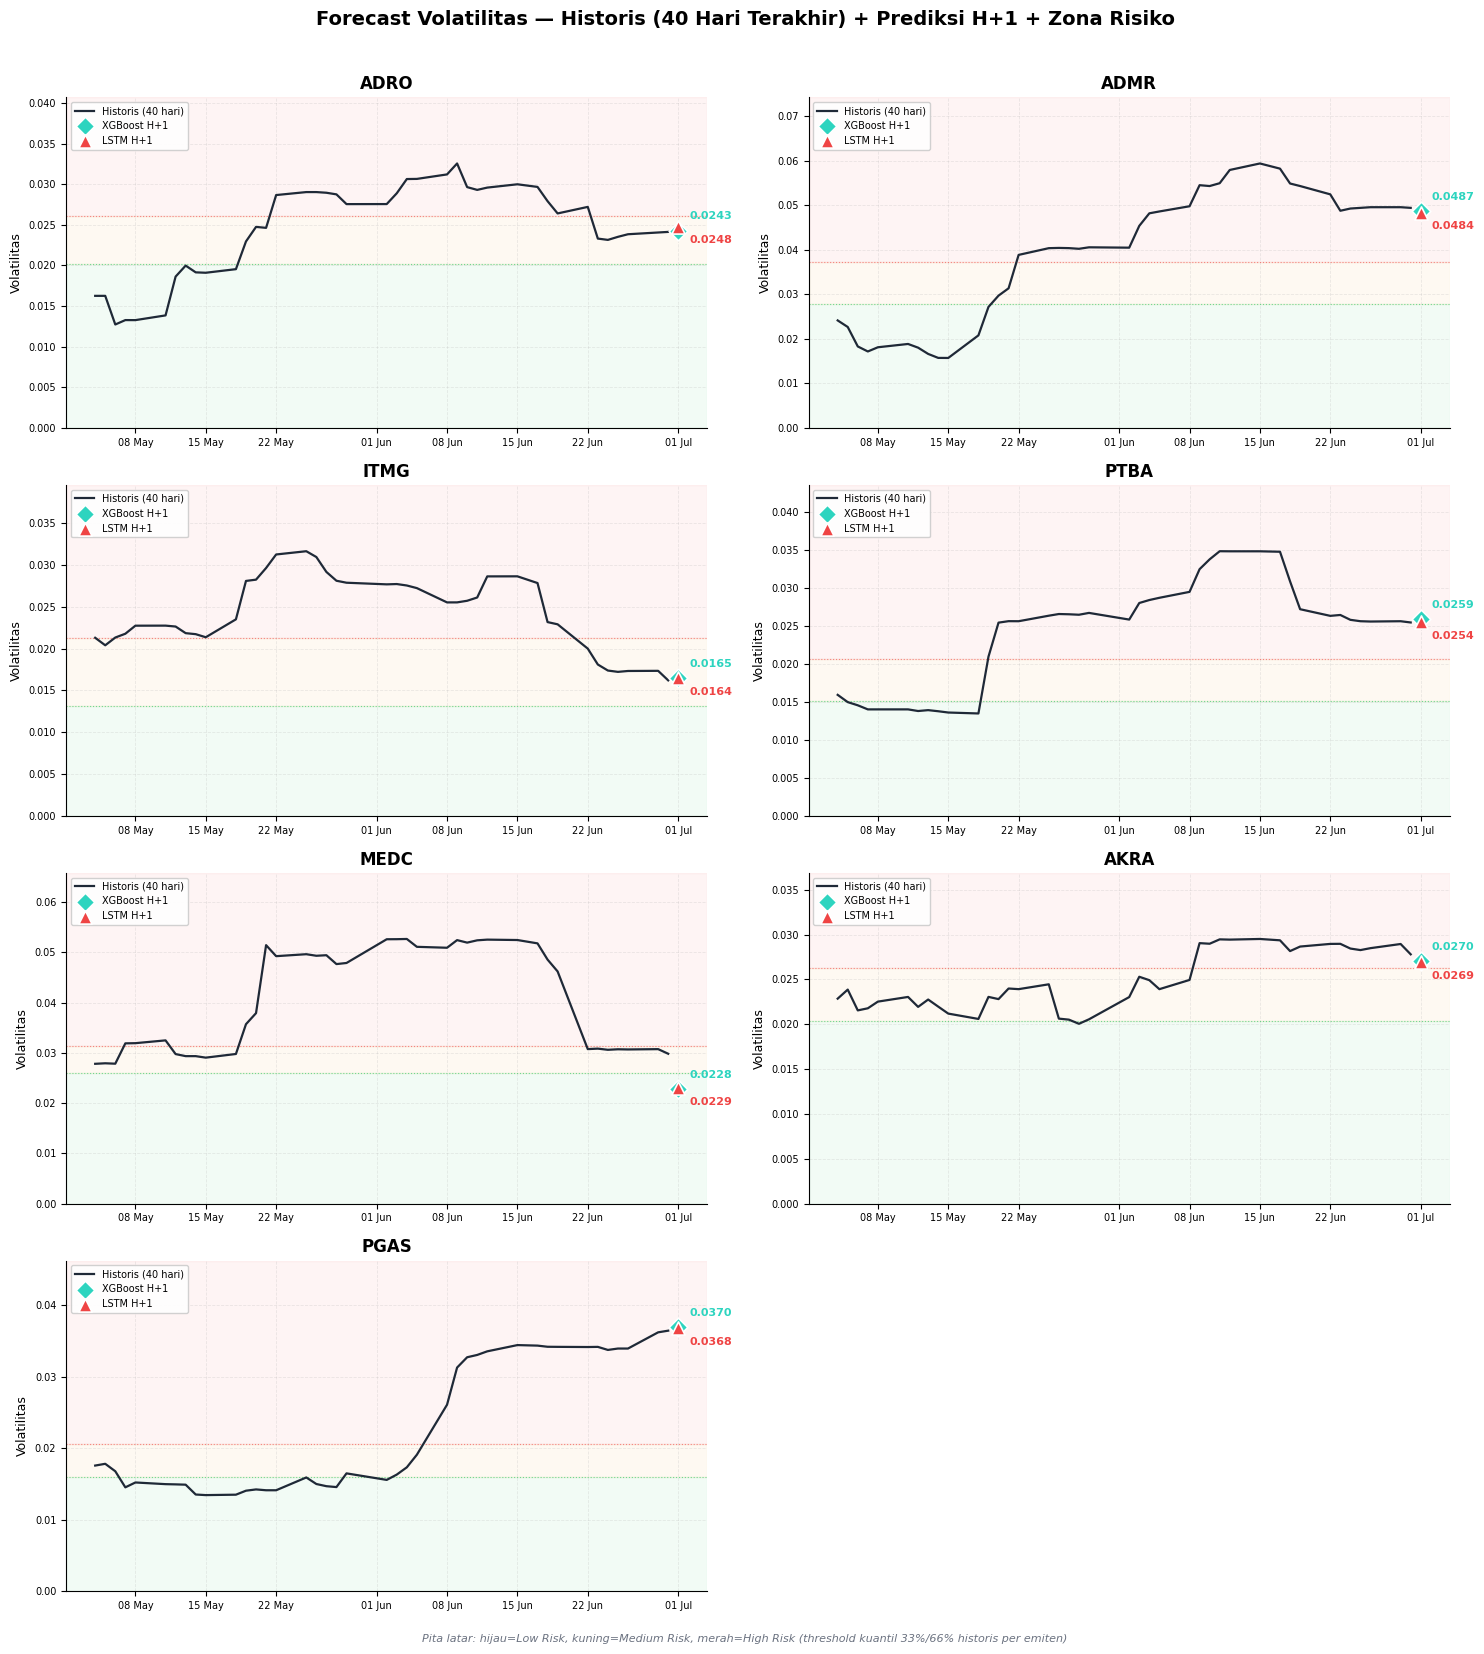

💾 Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_forecast_out_of_sample.png

✅ FORECAST OUT-OF-SAMPLE SELESAI
   H+1 (valid)        : tabel_forecast_h1.csv


In [11]:
print('='*70)
print('  📊 VISUALISASI FORECAST PER EMITEN (VERSI DIPERBARUI)')
print('='*70)

import matplotlib.dates as mdates

# ── Palet warna konsisten dengan dashboard (Low=hijau, Medium=amber, High=merah) ──
WARNA = {
    'historis': '#1f2937',      # abu gelap netral, bukan biru default matplotlib
    'xgboost':  '#2DD4BF',      # teal — aksen model utama
    'lstm':     '#EF4444',      # merah — model pembanding
    'rekursif': '#94A3B8',      # abu terang, garis putus-putus
    'zona_low':    '#22C55E',
    'zona_medium': '#F5A623',
    'zona_high':   '#EF4444',
}

emiten_ok = [e for e in URUTAN_EMITEN if e in hasil_xgb_h1 and e in hasil_lstm_h1]
ncol = 2; nrow = int(np.ceil(len(emiten_ok) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 4 * nrow))
axes = np.array(axes).ravel()

for ax, emiten in zip(axes, emiten_ok):
    d_hist = df_tek[df_tek['Emiten'] == emiten].sort_values('Date').tail(40)
    hist_vol = df_tek[df_tek['Emiten'] == emiten][KOLOM_Y].dropna()  # basis kuantil, sama seperti CELL 6

    # ── Pita latar zona risiko (Low/Medium/High) — konteks visual langsung ──
    q33, q66 = hitung_threshold_risiko(hist_vol)
    y_max_plot = max(d_hist['Volatilitas'].max(),
                      hasil_xgb_h1[emiten]['Vol_Prediksi_H1'],
                      hasil_lstm_h1[emiten]['Vol_Prediksi_H1']) * 1.25
    ax.axhspan(0, q33, color=WARNA['zona_low'], alpha=0.06, zorder=0)
    ax.axhspan(q33, q66, color=WARNA['zona_medium'], alpha=0.06, zorder=0)
    ax.axhspan(q66, y_max_plot, color=WARNA['zona_high'], alpha=0.06, zorder=0)

    # ── Garis historis ──
    ax.plot(d_hist['Date'], d_hist['Volatilitas'], color=WARNA['historis'],
             lw=1.6, label='Historis (40 hari)', zorder=5)

    # ── Titik prediksi H+1, dengan label nilai langsung di grafik ──
    tgl_h1 = hasil_xgb_h1[emiten]['Tanggal_Basis'] + pd.Timedelta(days=1)
    v_xgb  = hasil_xgb_h1[emiten]['Vol_Prediksi_H1']
    v_lstm = hasil_lstm_h1[emiten]['Vol_Prediksi_H1']

    ax.scatter([tgl_h1], [v_xgb], color=WARNA['xgboost'], marker='D', s=90,
               zorder=6, edgecolor='white', linewidth=1.2, label='XGBoost H+1')
    ax.annotate(f'{v_xgb:.4f}', xy=(tgl_h1, v_xgb), xytext=(8, 8),
                textcoords='offset points', fontsize=8, fontweight='bold',
                color=WARNA['xgboost'])

    ax.scatter([tgl_h1], [v_lstm], color=WARNA['lstm'], marker='^', s=90,
               zorder=6, edgecolor='white', linewidth=1.2, label='LSTM H+1')
    ax.annotate(f'{v_lstm:.4f}', xy=(tgl_h1, v_lstm), xytext=(8, -12),
                textcoords='offset points', fontsize=8, fontweight='bold',
                color=WARNA['lstm'])

    # ── Garis putus threshold Q33/Q66 (referensi visual batas zona) ──
    ax.axhline(q33, color=WARNA['zona_low'], lw=0.8, ls=':', alpha=0.6)
    ax.axhline(q66, color=WARNA['zona_high'], lw=0.8, ls=':', alpha=0.6)

    # ── Rekursif ilustratif (kalau aktif) ──
    if JALANKAN_MODE_REKURSIF and emiten in hasil_rekursif:
        dfr = hasil_rekursif[emiten]
        ax.plot(dfr['Tanggal_Estimasi'], dfr['Vol_Prediksi'],
                color=WARNA['rekursif'], lw=1.2, linestyle=':', marker='.',
                markersize=4, alpha=0.8, label='Rekursif (ilustratif)')

    ax.set_title(emiten, fontweight='bold', fontsize=12)
    ax.set_ylabel('Volatilitas', fontsize=9)
    ax.set_ylim(0, y_max_plot)
    ax.legend(fontsize=7, loc='upper left', framealpha=0.9)
    ax.tick_params(labelsize=7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.grid(alpha=0.25, linestyle='--', linewidth=0.6)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

for ax in axes[len(emiten_ok):]:
    ax.axis('off')

fig.suptitle('Forecast Volatilitas — Historis (40 Hari Terakhir) + Prediksi H+1 + Zona Risiko',
             fontweight='bold', fontsize=14, y=1.01)
fig.text(0.5, -0.01,
         'Pita latar: hijau=Low Risk, kuning=Medium Risk, merah=High Risk (threshold kuantil 33%/66% historis per emiten)',
         ha='center', fontsize=8, style='italic', color='#6b7280')

plt.tight_layout()
path_fig = DIR_GAMBAR / 'gambar_forecast_out_of_sample.png'
plt.savefig(path_fig, dpi=200, bbox_inches='tight')
plt.show()
print(f'💾 Gambar disimpan: {path_fig}')

print()
print('='*70)
print('✅ FORECAST OUT-OF-SAMPLE SELESAI')
print(f'   H+1 (valid)        : tabel_forecast_h1.csv')
if JALANKAN_MODE_REKURSIF:
    print(f'   H+1..H+N (ilustratif): tabel_forecast_rekursif_ilustratif.csv')
print('='*70)